# Survival Analysis of Patients with Lung Adenocarcinoma Using Clinical Data and Driver Gene Mutation

Lung adenocarcinoma is the most common subtype of lung cancer and a major cause of cancer-related mortality. After diagnosis, survival prognosis plays an important role in treatment planning and shared decision-making. Currently, survival estimates largely rely on cancer staging, which provides population-level estimates but has limitations in predicting individual outcomes.

This project aims to develop a personalized survival prediction model using Cox proportional hazards regression, incorporating clinical characteristics, cancer stage, and selected genetic alterations. Data from The Cancer Genome Atlas Lung Adenocarcinoma (TCGA-LUAD) cohort will be used for model development, with external validation using the Clinical Proteomic Tumor Analysis Consortium (CPTAC-3) cohort.

The objective is to identify factors associated with overall survival, particularly the prognostic impact of cancer-related genetic alterations, and explore the potential of an individualized clinical and genomic-based survival prediction tool to support patient counseling and treatment planning.

## Import Packages and Load Dataset


### Import packages

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test
from lifelines.plotting import add_at_risk_counts

from IPython.display import display
from lifelines.utils import concordance_index

### Load dataset

#### 1. Data Source and Access Information
- **Repository:** National Cancer Institute (NCI) Genomic Data Commons (GDC) Data Portal
- **Project ID:** `TCGA-LUAD` (The Cancer Genome Atlas - Lung Adenocarcinoma)
- **Data Portal URL:** [https://portal.gdc.cancer.gov/projects/TCGA-LUAD](https://portal.gdc.cancer.gov/projects/TCGA-LUAD)
- **Date of Data Access:** **October 13, 2026**

#### 2. Downloaded Files & Directory Architecture

| Category | File Name | Description |
| :--- | :--- | :--- |
| **Clinical Profile** | `clinical.tsv` | Patient demographics, primary tumor diagnosis, AJCC pathologic stage, and pathologic TNM descriptors. |
| **Follow-up Record** | `follow_up.tsv` | Longitudinal patient tracking intervals (`days_to_follow_up`). |
| **Cohort Definition** | `cohort_TCGA_LUAD_somatic_mutation.2026-10-13.tsv` | Quality-controlled patient cohort possessing verified whole-exome somatic mutation profiles. |
| **Genomic Markers** | `cohort_TCGA_LUAD_{GENE}.2026-10-13.tsv` | Gene-specific mutation positive lists for `KEAP1`, `STK11`, `SMARCA4`, and `TP53`. |

In [2]:
root = Path.cwd()
if not (root / 'data').exists():
    root = root.parent

data_dir = root / 'data' / 'clinical.project-tcga-luad.2026-10-13'

missing_values = [
    "'--", "--", "Unknown", "unknown",
    "Not Reported", "not reported",
]

clinical = pd.read_csv(
    data_dir / 'clinical.tsv',
    sep='\t',
    na_values=missing_values,
    low_memory=False,
)

follow_up = pd.read_csv(
    data_dir / 'follow_up.tsv',
    sep='\t',
    na_values=missing_values,
    low_memory=False,
)

key = 'cases.case_id'

cohort_path = data_dir / 'cohort_TCGA_LUAD_somatic_mutation.2026-10-13.tsv'
cohort = pd.read_csv(cohort_path, sep='\t', dtype={"id": "string"})
cohort_ids = cohort["id"].dropna().str.strip()
cohort_ids = set(cohort_ids[cohort_ids.ne("")])

clinical[key] = clinical[key].astype("string").str.strip()
follow_up[key] = follow_up[key].astype("string").str.strip()

clinical = clinical.loc[clinical[key].isin(cohort_ids)].copy()
follow_up = follow_up.loc[follow_up[key].isin(cohort_ids)].copy()

patient_columns = [
    key,
    "demographic.sex_at_birth",
    "demographic.vital_status",
    "demographic.days_to_death",
]

patients = (
    clinical[patient_columns]
    .drop_duplicates()
    .rename(columns={
        "demographic.sex_at_birth": "sex",
        "demographic.vital_status": "vital_status",
        "demographic.days_to_death": "days_to_death",
    })
)

assert patients[key].is_unique, (
    "พบข้อมูล demographic หลายชุดต่อผู้ป่วย ต้องตรวจความขัดแย้ง"
)

patients["days_to_death"] = pd.to_numeric(
    patients["days_to_death"], errors="coerce"
)

is_primary = (
    clinical["diagnoses.diagnosis_is_primary_disease"]
    .astype("string")
    .str.lower()
    .eq("true")
    .fillna(False)
)

diagnosis_columns = {
    "diagnoses.age_at_diagnosis": "age_at_diagnosis_days",
    "diagnoses.ajcc_pathologic_stage": "pathologic_stage",
    "diagnoses.ajcc_pathologic_t": "t",
    "diagnoses.ajcc_pathologic_n": "n",
    "diagnoses.ajcc_pathologic_m": "m",
}

primary_diagnosis = (
    clinical.loc[is_primary, [key, *diagnosis_columns]]
    .rename(columns=diagnosis_columns)
    .drop_duplicates()
)

primary_diagnosis["age"] = (
    pd.to_numeric(
        primary_diagnosis["age_at_diagnosis_days"],
        errors="coerce",
    )
    / 365.25
)

primary_diagnosis = primary_diagnosis.replace({
    "t": {"TX": pd.NA},
    "n": {"NX": pd.NA},
    "m": {"MX": pd.NA},
})

clinical_times = clinical.loc[
    is_primary, [key, "diagnoses.days_to_last_follow_up"]
].rename(columns={
    "diagnoses.days_to_last_follow_up": "followup_days",
})

followup_times = follow_up[
    [key, "follow_ups.days_to_follow_up"]
].rename(columns={
    "follow_ups.days_to_follow_up": "followup_days",
})

times = pd.concat(
    [clinical_times, followup_times],
    ignore_index=True,
)

times["followup_days"] = pd.to_numeric(
    times["followup_days"], errors="coerce"
)

latest_followup = (
    times.groupby(key, as_index=False)["followup_days"].max()
)

merged = (
    patients
    .merge(
        primary_diagnosis,
        on=key,
        how="left",
        validate="one_to_one",
    )
    .merge(
        latest_followup,
        on=key,
        how="left",
        validate="one_to_one",
    )
)

merged["status"] = (
    merged["vital_status"]
    .map({"Dead": 1, "Alive": 0})
    .astype("Int64")
)

merged["overall_survival"] = pd.Series(
    pd.NA,
    index=merged.index,
    dtype="Float64",
)

dead = merged["status"].eq(1).fillna(False)
alive = merged["status"].eq(0).fillna(False)

merged.loc[dead, "overall_survival"] = (
    merged.loc[dead, "days_to_death"]
)
merged.loc[alive, "overall_survival"] = (
    merged.loc[alive, "followup_days"]
)

df = merged.rename(columns={key: "case_id"})[
    [
        "case_id",
        "age",
        "sex",
        "pathologic_stage",
        "t",
        "n",
        "m",
        "overall_survival",
        "status",
    ]
].copy()

assert df["case_id"].is_unique
df.head()

,case_id,age,sex,pathologic_stage,t,n,m,overall_survival,status
0,0075437e-ba1a-46be-86d6-9773209a2b5e,64.856947,male,Stage IIB,T2b,N1,M0,1246.0,0
1,009be09b-f9f6-43b7-8f45-4a648f8123ce,84.068446,female,Stage IB,T2,N0,M0,427.0,0
2,01e9888d-b5b9-48f1-8ba6-8a89af108a04,49.629021,male,Stage IIIA,T4,N1,M0,617.0,0
3,0232d299-4cdf-4fd7-9a5e-8d13c208b40c,59.764545,male,Stage IIIA,T2,N2,<NA>,224.0,0
4,028e99e9-5b9a-4954-bb6e-6d4709a3cea8,NaN,female,Stage IB,T2,N0,M0,3261.0,0


## Exploratory Data Analysis

### Basic information about the data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 559 entries, 0 to 558
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   case_id           559 non-null    string 
 1   age               478 non-null    float64
 2   sex               509 non-null    object 
 3   pathologic_stage  501 non-null    object 
 4   t                 506 non-null    object 
 5   n                 497 non-null    object 
 6   m                 367 non-null    object 
 7   overall_survival  500 non-null    Float64
 8   status            509 non-null    Int64  
dtypes: Float64(1), Int64(1), float64(1), object(5), string(1)
memory usage: 40.5+ KB


In [4]:
df.head()

,case_id,age,sex,pathologic_stage,t,n,m,overall_survival,status
0,0075437e-ba1a-46be-86d6-9773209a2b5e,64.856947,male,Stage IIB,T2b,N1,M0,1246.0,0
1,009be09b-f9f6-43b7-8f45-4a648f8123ce,84.068446,female,Stage IB,T2,N0,M0,427.0,0
2,01e9888d-b5b9-48f1-8ba6-8a89af108a04,49.629021,male,Stage IIIA,T4,N1,M0,617.0,0
3,0232d299-4cdf-4fd7-9a5e-8d13c208b40c,59.764545,male,Stage IIIA,T2,N2,<NA>,224.0,0
4,028e99e9-5b9a-4954-bb6e-6d4709a3cea8,NaN,female,Stage IB,T2,N0,M0,3261.0,0


### Data imputation

#### Pathologic Stage Imputation

In [5]:
df[df['pathologic_stage'].isna()].head()

,case_id,age,sex,pathologic_stage,t,n,m,overall_survival,status
6,03c3409a-9d16-41d0-9e26-f9fc2547a4c8,74.965092,male,NaN,T2a,N0,M0,38.0,1
10,07119baf-64a7-454c-b1b0-c769b506a63d,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>
26,0d96def2-cf0a-4659-94e5-f08744c57cc6,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>
48,175cb088-9b10-4fa9-95c0-7837fdc7bcf9,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>
54,19ca36e6-2154-4224-89b1-117a4a4407f6,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,<NA>


Following exploratory data analysis of missing clinical features, missing pathologic stage values were logically reconstructed using the standardized AJCC TNM Staging Classification:

Staging Framework:

- Stage IV: Any distant metastasis (M1, including M1a, M1b, M1c).
- Stage III: Locally advanced disease with N2 or N3 nodal involvement, T4 tumor extension, or T3 with N1.
- Stage II: Intermediate disease characterized by T3 N0, T1/T2 with N1, or T2b N0 (AJCC Stage IIA criteria).
- Stage I: Localized disease including T1 N0 and T2a N0.

In [6]:
def tnm_to_stage(row):
    t_val = row['t']
    n_val = row['n']
    m_val = row['m']
    
    t = str(t_val).lower().strip() if pd.notna(t_val) else ""
    n = str(n_val).lower().strip() if pd.notna(n_val) else ""
    m = str(m_val).lower().strip() if pd.notna(m_val) else ""
    
    if m.startswith('m1'):
        return 'Stage IV'
    
    if n.startswith(('n2', 'n3')) or t.startswith('t4') or (t.startswith('t3') and n.startswith('n1')):
        return 'Stage III'
    
    if (t.startswith('t3') and n.startswith('n0')) or \
       (t.startswith(('t1', 't2')) and n.startswith('n1')) or \
       (t.startswith('t2b') and n.startswith('n0')):
        return 'Stage II'
    
    if (t.startswith('t1') or t in ('t2', 't2a')) and n.startswith('n0'):
        return 'Stage I'
    
    return np.nan

mask = df['pathologic_stage'].isna()
df.loc[mask, 'pathologic_stage'] = df[mask].apply(tnm_to_stage, axis=1)

In [7]:
stage_map = {
    'Stage I': 'I', 'Stage IA': 'I', 'Stage IA1': 'I', 'Stage IA2': 'I', 'Stage IA3': 'I', 'Stage IB': 'I',
    'Stage II': 'II', 'Stage IIA': 'II', 'Stage IIB': 'II',
    'Stage III': 'III', 'Stage IIIA': 'III', 'Stage IIIB': 'III', 'Stage IIIC': 'III',
    'Stage IV': 'IV', 'Stage IVA': 'IV', 'Stage IVB': 'IV',
}

df['pathologic_stage'] = df['pathologic_stage'].map(stage_map)
df = df.drop(columns=["t", "n", "m"])

### Data Joining: Integrating Mutation Profiles

Four somatic driver genes (KEAP1, STK11, SMARCA4, and TP53) were selected based on three criteria:

1. Prognostic & Biological Impact: 
   Extensive clinical evidence links mutations in these four genes to aggressive tumor biology, shortened overall survival, and therapeutic resistance (e.g., STK11 and KEAP1 are well-documented drivers of primary resistance to immunotherapy and chemotherapy, while TP53 and SMARCA4 confer genomic instability and poor clinical outcomes).

2. Management-Independent Survival Biomarkers: 
   The study specifically focuses on genes with strong intrinsic prognostic potential for survival analysis, while intentionally excluding genes used to direct clinical management plans (such as actionable driver oncogenes like EGFR or ALK). Because the selected four genes do not dictate specific targeted therapy pathways, they allow us to evaluate baseline survival risks without confounding caused by differing treatment management strategies.

3. Sufficient Sample Size: 
   Each selected gene exhibits a high enough mutation prevalence in this cohort to preserve adequate statistical power for multivariable survival modeling.

In [8]:
mutation_dir = data_dir / "tcga-mutated-gene"

mutation_files = {
    "keap1": "cohort_TCGA_LUAD_KEAP1.2026-10-13.tsv",
    "stk11": "cohort_TCGA_LUAD_STK11.2026-10-13.tsv",
    "smarca4": "cohort_TCGA_LUAD_SMARCA4.2026-10-13.tsv",
    "tp53": "cohort_TCGA_LUAD_TP53.2026-10-13.tsv",
}

case_id = df["case_id"].astype("string").str.strip()

for gene, filename in mutation_files.items():
    mutation = pd.read_csv(
        mutation_dir / filename,
        sep="\t",
        dtype={"id": "string"},
    )

    positive_ids = mutation["id"].dropna().str.strip()

    df[gene] = case_id.isin(positive_ids).astype("Int64")
    df.loc[case_id.isna(), gene] = pd.NA

### Check missing values

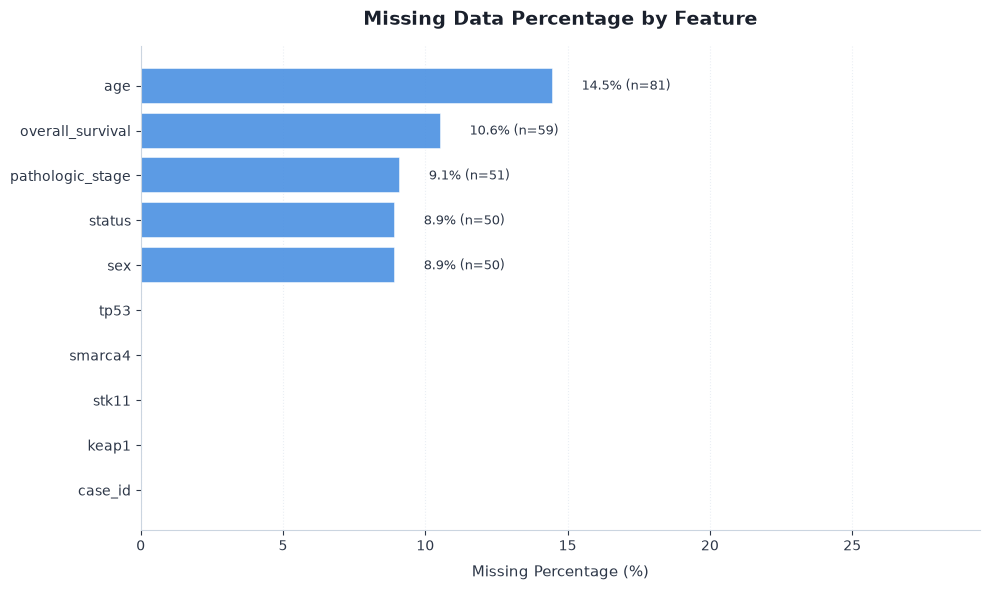

In [9]:
missing_df = (
    df.isna()
    .agg(["mean", "sum"])
    .T.rename(columns={"mean": "pct", "sum": "count"})
)
missing_df["pct"] = missing_df["pct"] * 100
missing_df = missing_df.sort_values(by="pct", ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    missing_df.index,
    missing_df["pct"],
    color="#4A90E2",
    edgecolor="white",
    linewidth=1.2,
    alpha=0.90,
)

for bar, (_, row) in zip(bars, missing_df.iterrows()):
    width = bar.get_width()
    if width > 0:
        ax.text(
            width + 1.0,
            bar.get_y() + bar.get_height() / 2,
            f"{width:.1f}% (n={int(row['count']):,})",
            va="center",
            fontsize=9,
            color="#2D3748",
        )

ax.set_title(
    "Missing Data Percentage by Feature",
    fontsize=14,
    fontweight="bold",
    color="#1A202C",
    pad=15,
)
ax.set_xlabel("Missing Percentage (%)", fontsize=11, color="#2D3748", labelpad=8)
max_pct = missing_df["pct"].max()
ax.set_xlim(0, max(max_pct + 15, 20) if max_pct > 0 else 10)

ax.grid(axis="x", linestyle=":", alpha=0.7, color="#E2E8F0")
ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_color("#CBD5E0")
ax.spines["bottom"].set_color("#CBD5E0")

ax.tick_params(colors="#2D3748", labelsize=10)
plt.tight_layout()
plt.show()

- Removed cases with remaining missing values and dropped TNM columns.
- Filtered for positive follow-up durations (overall survival > 0 days) in preparation for downstream survival models.

In [10]:
df = df.dropna(subset=['age', 'sex', 'pathologic_stage', 'overall_survival', 'status'])
df = df[df['overall_survival'] > 0].copy()

### Check duplicated

In [11]:
total_duplicates = df.duplicated().sum()
print(f"Total duplicate rows: {total_duplicates}")

if "case_id" in df.columns:
    id_duplicates = df.duplicated(subset=["case_id"]).sum()
    print(f"Duplicate patient IDs (case_id): {id_duplicates}")

if total_duplicates > 0:
    print("\nSample duplicate records:")
    display(df[df.duplicated(keep=False)].head())
else:
    print("Verification passed: No duplicate records found.")

Total duplicate rows: 0
Duplicate patient IDs (case_id): 0
Verification passed: No duplicate records found.


### Check outliers

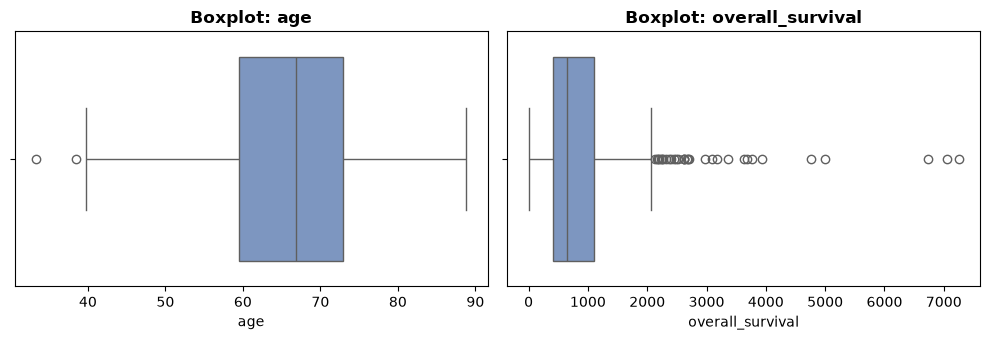

In [12]:
cols = ["age", "overall_survival"] 

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, col in zip(axes, cols):
    sns.boxplot(x=df[col], ax=ax, color="#7293CB")
    ax.set_title(f"Boxplot: {col}", fontweight="bold")

plt.tight_layout()
plt.show()

### Data visualization

In [13]:
df_final = df.copy()
df_final.head()

,case_id,age,sex,pathologic_stage,overall_survival,status,keap1,stk11,smarca4,tp53
0,0075437e-ba1a-46be-86d6-9773209a2b5e,64.856947,male,II,1246.0,0,0,1,0,1
1,009be09b-f9f6-43b7-8f45-4a648f8123ce,84.068446,female,I,427.0,0,0,0,0,0
2,01e9888d-b5b9-48f1-8ba6-8a89af108a04,49.629021,male,III,617.0,0,0,0,0,0
3,0232d299-4cdf-4fd7-9a5e-8d13c208b40c,59.764545,male,III,224.0,0,1,0,0,1
5,035c0b2b-c722-443b-8962-db4ee92c7532,73.396304,female,II,179.0,0,0,0,0,1


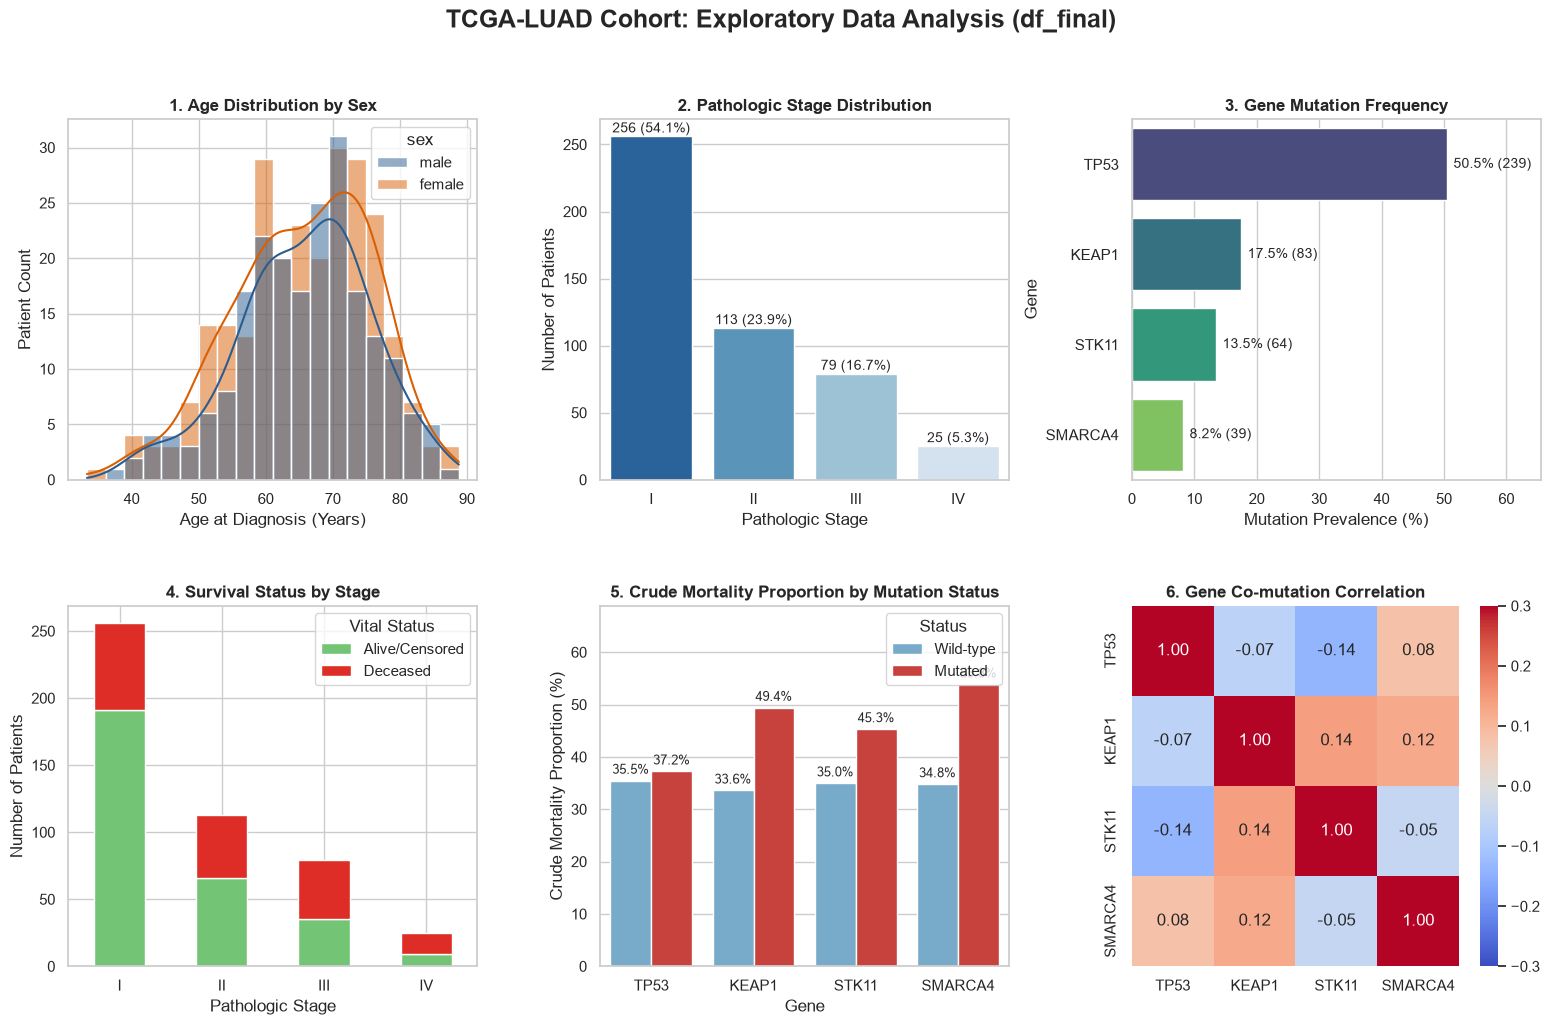

In [14]:
sns.set_theme(style="whitegrid", font_scale=1.0)
fig, axes = plt.subplots(2, 3, figsize=(19, 11))
plt.subplots_adjust(hspace=0.35, wspace=0.3)

genes = ["tp53", "keap1", "stk11", "smarca4"]

sns.histplot(
    data=df_final, 
    x="age", 
    hue="sex", 
    kde=True, 
    bins=20, 
    palette={"male": "#2b5c8f", "female": "#d95f02"},
    ax=axes[0, 0]
)
axes[0, 0].set_title("1. Age Distribution by Sex", fontweight="bold")
axes[0, 0].set_xlabel("Age at Diagnosis (Years)")
axes[0, 0].set_ylabel("Patient Count")

stage_counts = df_final["pathologic_stage"].value_counts().reindex(["I", "II", "III", "IV"]).fillna(0)
sns.barplot(
    x=stage_counts.index, 
    y=stage_counts.values, 
    hue=stage_counts.index,
    palette="Blues_r", 
    legend=False,
    ax=axes[0, 1]
)
for i, v in enumerate(stage_counts.values):
    axes[0, 1].text(i, v + 3, f"{int(v)} ({v/len(df_final)*100:.1f}%)", ha="center", fontsize=10)
axes[0, 1].set_title("2. Pathologic Stage Distribution", fontweight="bold")
axes[0, 1].set_xlabel("Pathologic Stage")
axes[0, 1].set_ylabel("Number of Patients")

mut_freq = (df_final[genes].sum() / len(df_final) * 100).sort_values(ascending=False)
gene_labels = [g.upper() for g in mut_freq.index]

sns.barplot(
    x=mut_freq.values, 
    y=gene_labels, 
    hue=gene_labels,
    palette="viridis", 
    legend=False,
    ax=axes[0, 2]
)
for i, v in enumerate(mut_freq.values):
    axes[0, 2].text(v + 1, i, f"{v:.1f}% ({int(df_final[mut_freq.index[i]].sum())})", va="center", fontsize=10)
axes[0, 2].set_xlim(0, max(mut_freq.values) + 15)
axes[0, 2].set_title("3. Gene Mutation Frequency", fontweight="bold")
axes[0, 2].set_xlabel("Mutation Prevalence (%)")
axes[0, 2].set_ylabel("Gene")

stage_status = pd.crosstab(
    df_final["pathologic_stage"], 
    df_final["status"].map({0: "Alive/Censored", 1: "Deceased"})
).reindex(["I", "II", "III", "IV"])

stage_status.plot(
    kind="bar", 
    stacked=True, 
    color=["#74c476", "#de2d26"], 
    ax=axes[1, 0], 
    rot=0
)
axes[1, 0].set_title("4. Survival Status by Stage", fontweight="bold")
axes[1, 0].set_xlabel("Pathologic Stage")
axes[1, 0].set_ylabel("Number of Patients")
axes[1, 0].legend(title="Vital Status", loc="upper right")

records = []
for g in genes:
    for val, label in [(0, "Wild-type"), (1, "Mutated")]:
        subset = df_final[df_final[g] == val]
        total = len(subset)
        deaths = (subset["status"] == 1).sum()
        death_rate = (deaths / total * 100) if total > 0 else 0
        records.append({
            "Gene": g.upper(),
            "Type": label,
            "Death Rate (%)": death_rate,
            "Deaths": deaths,
            "Total": total
        })

gene_status_df = pd.DataFrame(records)

p5 = sns.barplot(
    data=gene_status_df, 
    x="Gene", 
    y="Death Rate (%)", 
    hue="Type", 
    palette={"Wild-type": "#6baed6", "Mutated": "#de2d26"},
    ax=axes[1, 1]
)

for p in p5.patches:
    height = p.get_height()
    if height > 0:
        p5.annotate(
            f"{height:.1f}%",
            (p.get_x() + p.get_width() / 2., height),
            ha="center", va="bottom",
            fontsize=9, xytext=(0, 3),
            textcoords="offset points"
        )

axes[1, 1].set_ylim(0, max(gene_status_df["Death Rate (%)"]) + 15)
axes[1, 1].set_title("5. Crude Mortality Proportion by Mutation Status", fontweight="bold")
axes[1, 1].set_xlabel("Gene")
axes[1, 1].set_ylabel("Crude Mortality Proportion (%)")
axes[1, 1].legend(title="Status", loc="upper right")

corr = df_final[genes].corr()
corr.index = [g.upper() for g in corr.index]
corr.columns = [g.upper() for g in corr.columns]

sns.heatmap(
    corr, 
    annot=True, 
    cmap="coolwarm", 
    vmin=-0.3, 
    vmax=0.3, 
    fmt=".2f", 
    cbar=True,
    ax=axes[1, 2]
)
axes[1, 2].set_title("6. Gene Co-mutation Correlation", fontweight="bold")

plt.suptitle("TCGA-LUAD Cohort: Exploratory Data Analysis (df_final)", fontsize=18, fontweight="bold", y=0.98)
plt.show()

## Survival Analysis, Results and Evaluation

### Kaplan-Meier Survival Analysis by Pathologic Stage

Evaluating overall survival (OS) across pathologic tumor stages (I–IV) using the Kaplan-Meier estimator:
- **Survival Curves:** Stratified by pathologic stage with 95% confidence intervals and censoring indicators (`|`).
- **Hypothesis Testing:** Evaluated using the omnibus (multisample) log-rank test to assess statistical significance across stage groups.
- **Time Horizon:** Capped at a 5-year follow-up with the corresponding number of patients at risk.

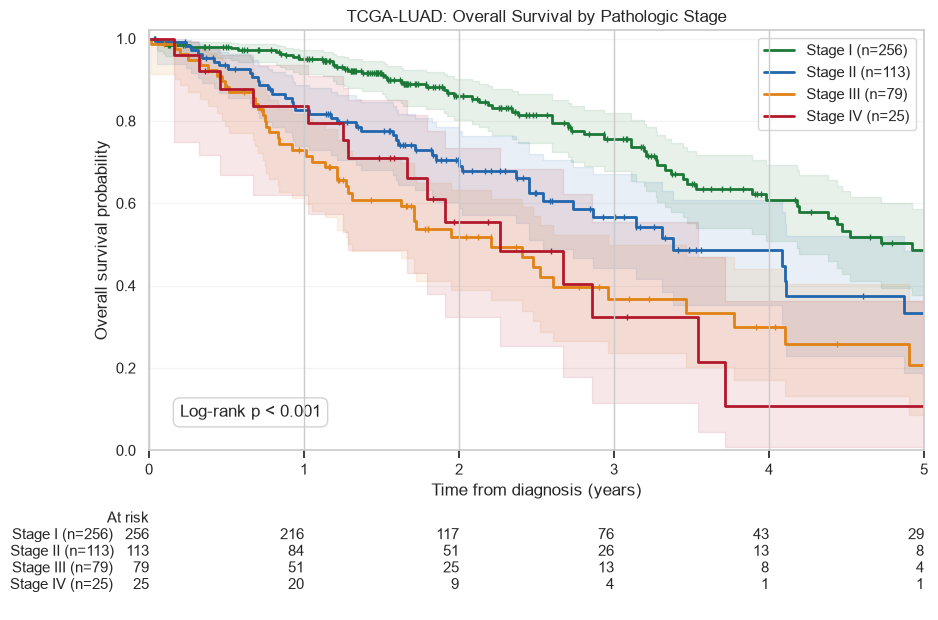

In [15]:
km_df = df_final.copy()
if "time_years" not in km_df.columns:
    km_df["time_years"] = km_df["overall_survival"] / 365.25

fig, ax = plt.subplots(figsize=(10, 7))
stage_colors = {"I": "#1b7837", "II": "#2166ac", "III": "#e08214", "IV": "#b2182b"}
fitters = []

for stage, color in stage_colors.items():
    group = km_df[km_df["pathologic_stage"] == stage]
    if group.empty:
        continue
    
    kmf = KaplanMeierFitter()
    kmf.fit(
        durations=group["time_years"], 
        event_observed=group["status"], 
        label=f"Stage {stage} (n={len(group)})"
    )
    kmf.plot_survival_function(
        ax=ax, 
        color=color, 
        ci_show=True, 
        ci_alpha=0.1, 
        show_censors=True, 
        censor_styles={"marker": "|", "ms": 5},
        linewidth=2
    )
    fitters.append(kmf)

logrank = multivariate_logrank_test(km_df["time_years"], km_df["pathologic_stage"], km_df["status"])
p_val_str = "p < 0.001" if logrank.p_value < 0.001 else f"p = {logrank.p_value:.3f}"
ax.text(0.04, 0.08, f"Log-rank {p_val_str}", transform=ax.transAxes, 
        bbox=dict(facecolor="white", edgecolor="lightgray", boxstyle="round,pad=0.4"))

ticks = np.arange(0, 6, 1)
ax.set(
    xlim=(0, 5), ylim=(0, 1.02), xticks=ticks,
    xlabel="Time from diagnosis (years)",
    ylabel="Overall survival probability",
    title="TCGA-LUAD: Overall Survival by Pathologic Stage"
)
ax.grid(alpha=0.2)
ax.legend(loc="upper right")

add_at_risk_counts(*fitters, ax=ax, xticks=ticks, rows_to_show=["At risk"])
fig.subplots_adjust(bottom=0.28)
plt.show()

### Multivariable Cox Proportional Hazards Model

A multivariable Cox proportional hazards model is fitted adjusting for baseline clinical characteristics (pathologic stage, age, and sex), followed by assessing the independent prognostic contribution of key somatic gene mutations (TP53, KEAP1, STK11, and SMARCA4).

In [16]:
cox_df = df_final.drop(columns=["case_id"], errors="ignore").copy()
cox_df["sex"] = pd.Categorical(cox_df["sex"], categories=["female", "male"])
cox_df["pathologic_stage"] = pd.Categorical(cox_df["pathologic_stage"], categories=["I", "II", "III", "IV"])

cox_df = pd.get_dummies(cox_df, columns=["sex", "pathologic_stage"], drop_first=True, dtype=float).astype(float)

cph = CoxPHFitter()
cph.fit(cox_df, duration_col="overall_survival", event_col="status")
cph.print_summary()

<lifelines.CoxPHFitter: fitted with 473 total observations, 301 right-censored observations>
             duration col = 'overall_survival'
                event col = 'status'
      baseline estimation = breslow
   number of observations = 473
number of events observed = 172
   partial log-likelihood = -878.22
         time fit was run = 2026-10-18 04:34:26 UTC

---
                      coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                             
age                   0.02      1.02      0.01           -0.00            0.03                1.00                1.03
keap1                 0.15      1.17      0.19           -0.22            0.53                0.80                1.70
stk11                 0.50      1.65      0.22            0.08            0.92                1.08                2.52
smarca4               0.42      1.53      0.25           -0.06            0.90                0.94                2.47
tp53                  0.23      1.25      0.16           -0.10            0.55                0.91                1.73
sex_male             -0.08      0.92      0.16           -0.40            0.23                0.67                1.26
pathologic_stage_II   0.68      1.97      0.20            0.29            1.07                1.34                2.91
pathologic_stage_III  1.15      3.15      0.20            0.76            1.54                2.14                4.65
pathologic_stage_IV   1.25      3.49      0.29            0.68            1.82                1.97                6.18

                      cmp to     z      p  -log2(p)
covariate                                          
age                     0.00  1.96   0.05      4.31
keap1                   0.00  0.80   0.42      1.24
stk11                   0.00  2.33   0.02      5.66
smarca4                 0.00  1.72   0.09      3.55
tp53                    0.00  1.37   0.17      2.56
sex_male                0.00 -0.51   0.61      0.71
pathologic_stage_II     0.00  3.41 <0.005     10.61
pathologic_stage_III    0.00  5.78 <0.005     27.01
pathologic_stage_IV     0.00  4.29 <0.005     15.75
---
Concordance = 0.69
Partial AIC = 1774.44
log-likelihood ratio test = 53.85 on 9 df
-log2(p) of ll-ratio test = 25.57

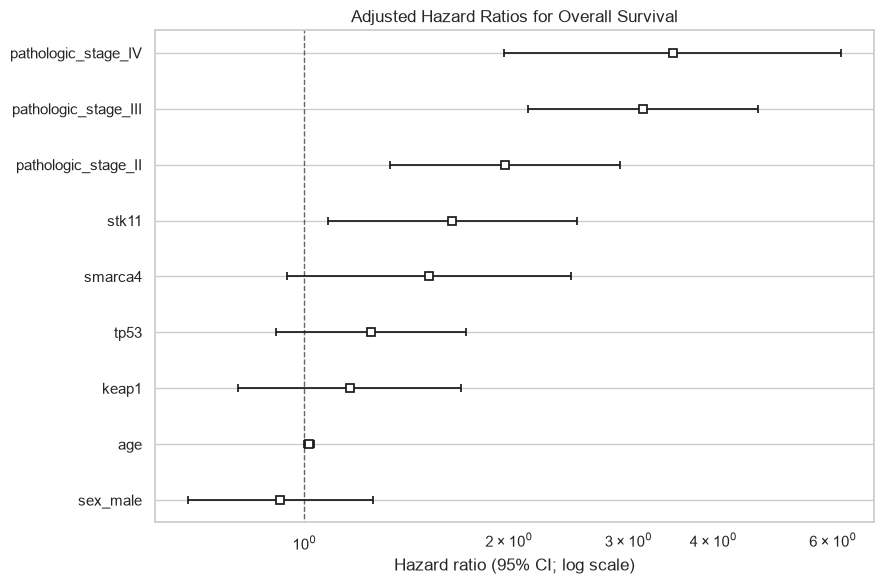

In [17]:
fig, ax = plt.subplots(figsize=(9, 6))

cph.plot(hazard_ratios=True, ax=ax)
ax.set_xscale("log")
ax.set_title("Adjusted Hazard Ratios for Overall Survival")
ax.set_xlabel("Hazard ratio (95% CI; log scale)")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

### Proportional Hazards Assumption Diagnostic


To validate the reliability of the Cox regression model, the **Proportional Hazards (PH) assumption** is evaluated across all covariates:
- **Statistical Test:** Scaled Schoenfeld residuals test to assess whether hazard ratios remain constant over time ($H_0$: hazard ratio is time-invariant).
- **Decision Rule:** A $p$-value $> 0.05$ indicates that the proportional hazards assumption holds for the respective covariate.


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...


   Bootstrapping lowess lines. May take a moment...

The ``p_value_threshold`` is set at 0.05. Even under the null hypothesis of no violations, some
covariates will be below the threshold by chance. This is compounded when there are many covariates.
Similarly, when there are lots of observations, even minor deviances from the proportional hazard
assumption will be flagged.

With that in mind, it's best to use a combination of statistical tests and visual tests to determine
the most serious violations. Produce visual plots using ``check_assumptions(..., show_plots=True)``
and looking for non-constant lines. See lin



1. Variable 'pathologic_stage_III' failed the non-proportional test: p-value is 0.0042.

   Advice: with so few unique values (only 2), you can include `strata=['pathologic_stage_III',
...]` in the call in `.fit`. See documentation in link [E] below.

   Bootstrapping lowess lines. May take a moment...


---
[A]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html
[B]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Bin-variable-and-stratify-on-it
[C]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Introduce-time-varying-covariates
[D]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Modify-the-functional-form
[E]  https://lifelines.readthedocs.io/en/latest/jupyter_notebooks/Proportional%20hazard%20assumption.html#Stratification



[[<Axes: xlabel='rank-transformed time\n(p=0.4283)'>,
  <Axes: xlabel='km-transformed time\n(p=0.2190)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0843)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0558)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.4831)'>,
  <Axes: xlabel='km-transformed time\n(p=0.3285)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.3639)'>,
  <Axes: xlabel='km-transformed time\n(p=0.6002)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.9086)'>,
  <Axes: xlabel='km-transformed time\n(p=0.9471)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.1112)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1618)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0971)'>,
  <Axes: xlabel='km-transformed time\n(p=0.1566)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.0042)'>,
  <Axes: xlabel='km-transformed time\n(p=0.0047)'>],
 [<Axes: xlabel='rank-transformed time\n(p=0.7067)'>,
  <Axes: xlabel='km-transformed time\n(p=0.6335)'>]]

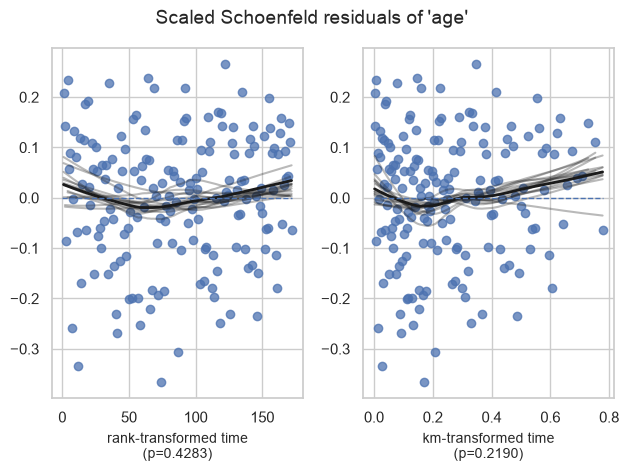

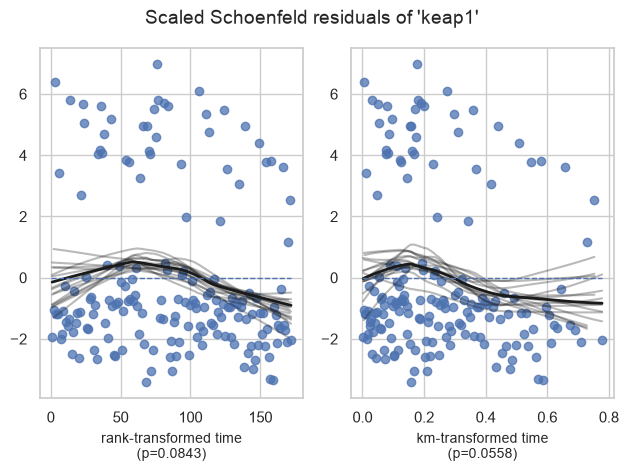

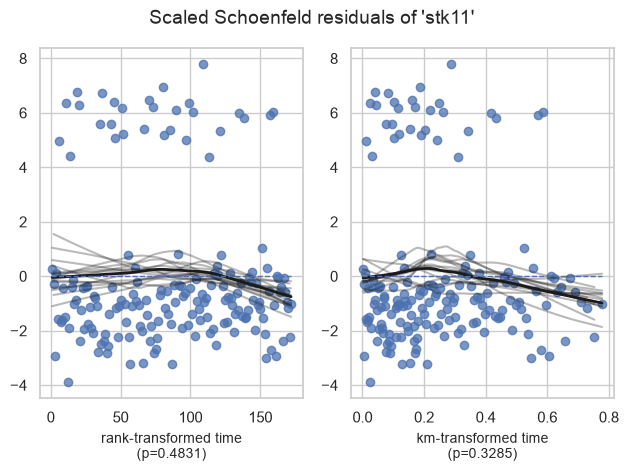

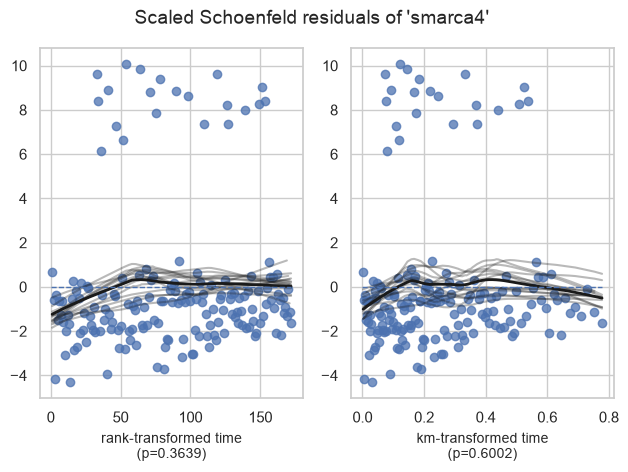

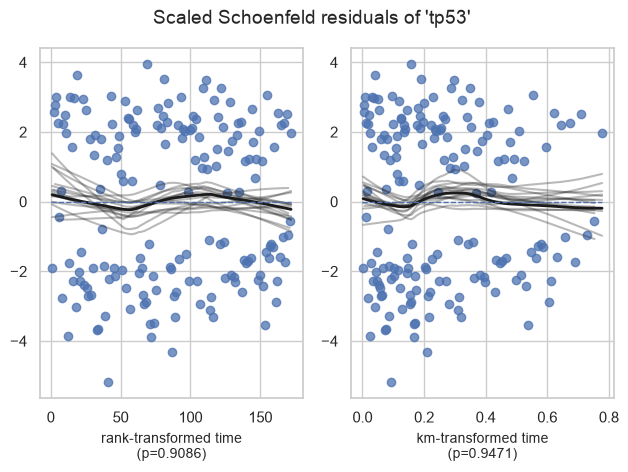

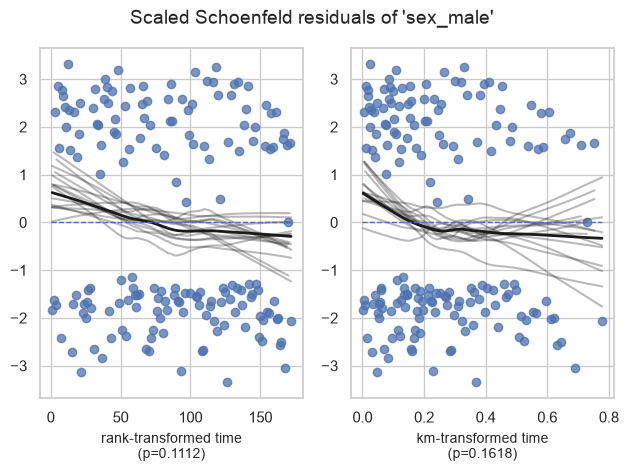

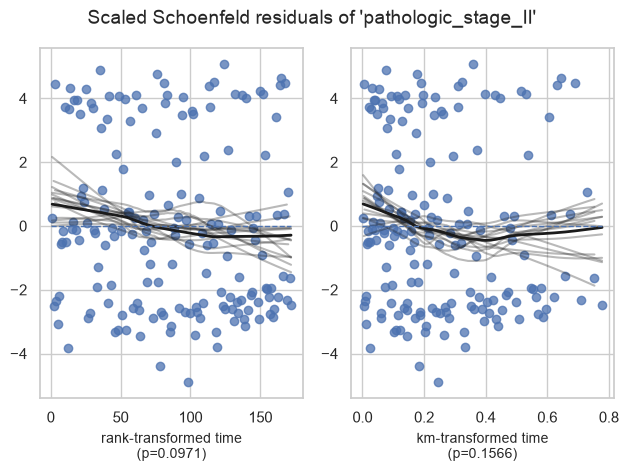

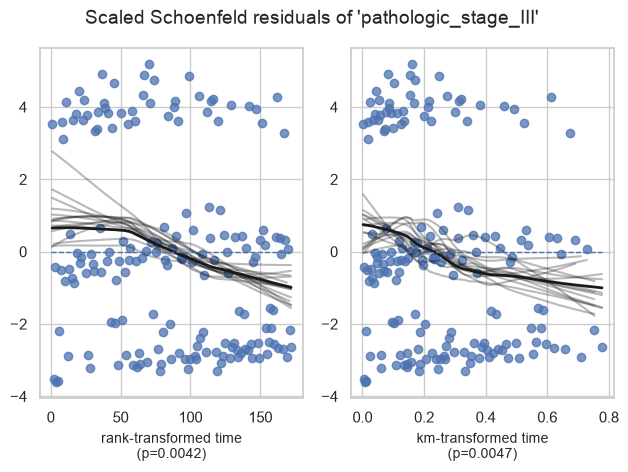

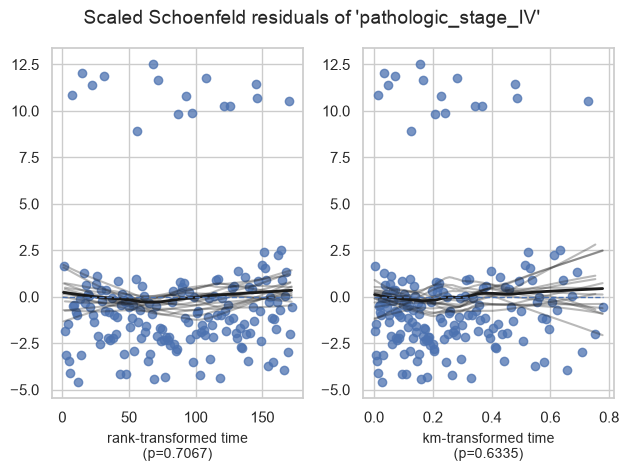

In [18]:
cph.check_assumptions(
    cox_df,
    p_value_threshold=0.05,
    show_plots=True,
)

- **Proportional Hazards Verification:** The scaled Schoenfeld residuals test confirms that the proportional hazards (PH) assumption holds across all four somatic gene mutations (`KEAP1`, `STK11`, `SMARCA4`, and `TP53`) as well as `age` and `sex` ($p > 0.05$). Only the baseline clinical covariate `pathologic_stage_III` showed time-varying deviation ($p = 0.0042$), which is clinically expected due to high early hazard rates in locally advanced disease.
- **Key Prognostic Drivers:**
  - **Genomic Factors:** `STK11` mutation demonstrates a statistically significant increase in mortality risk ($\text{HR} = 1.65, 95\%\ \text{CI}: 1.08\text{–}2.52, p = 0.020$), independent of tumor stage and patient demographics.
  - **Clinical Factors:** Tumor stage remains the dominant clinical determinant of survival, with Stage II–IV showing significantly elevated hazard ratios relative to Stage I ($p < 0.005$).
- **Conclusion:** All genomic biomarkers satisfy the proportional hazards assumption, and the multivariable Cox model reliably captures the independent prognostic impact of somatic mutations in TCGA-LUAD.

### Summary of Gene Mutation Prognostic Impact

In [19]:
mutated = ["keap1", "stk11", "smarca4", "tp53"]

mutated_results = cph.summary.loc[
    mutated, 
    ["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]
].rename(columns={
    "exp(coef)": "HR",
    "exp(coef) lower 95%": "95% CI Lower",
    "exp(coef) upper 95%": "95% CI Upper",
    "p": "p-value"
})

mutated_results.index = mutated_results.index.str.upper()
mutated_results.index.name = "Mutated Gene"
mutated_results = mutated_results.sort_values(by="HR")

display(mutated_results.round(3))

,HR,95% CI Lower,95% CI Upper,p-value
Mutated Gene,,,,
KEAP1,1.167,0.800,1.703,0.424
TP53,1.254,0.908,1.732,0.170
SMARCA4,1.526,0.943,2.469,0.085
STK11,1.651,1.083,2.517,0.020


- **STK11 (Significant Risk Factor):** 
  HR = 1.651 (95% CI: 1.083–2.517, p = 0.020)
  Patients with `STK11` mutations had a 65.1% higher hazard of death, confirming it as a statistically significant independent adverse prognostic marker.

- **SMARCA4 (Adverse Trend):** 
  HR = 1.526 (95% CI: 0.943–2.469, p = 0.085)
  Showed a borderline trend toward worse overall survival (52.6% increased hazard), though it did not reach the $\alpha = 0.05$ threshold after adjusting for clinical stage.

- **TP53 and KEAP1 (Non-Significant):** 
  `TP53` (HR = 1.254, 95% CI: 0.908–1.732, p = 0.170) and `KEAP1` (HR = 1.167, 95% CI: 0.800–1.703, p = 0.424) showed modest hazard increases, but neither was statistically significant in the multivariable model.

**STK11** was the only independent genomic predictor of poor overall survival in this cohort.

## External Validation and Calibration on CPTAC-3

### Load Dataset and Preprocessing

- **Repository:** National Cancer Institute (NCI) Genomic Data Commons (GDC) Data Portal
- **Project ID:** `CPTAC-3` (Clinical Proteomic Tumor Analysis Consortium - Lung Adenocarcinoma)
- **Data Portal URL:** [https://portal.gdc.cancer.gov/projects/CPTAC-3](https://portal.gdc.cancer.gov/projects/CPTAC-3)
- **Date of Data Access:** **October 14, 2026**

In [20]:
root = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
ext_dir = root / "data" / "clinical.project-cptac-3.2026-10-14"
gene_dir = ext_dir / "cptac-3-mutated-gene"
genes = ["keap1", "stk11", "smarca4", "tp53"]
na_vals = ["'--", "--", "Unknown", "unknown", "not reported", "Not Reported"]

cohort_ids = set(pd.read_csv(ext_dir / "cohort_CPTAC_3_LUAD_somatic_mutation.2026-10-14.tsv", sep="\t", dtype=str)["id"].dropna().str.strip())
clin = pd.read_csv(ext_dir / "clinical.tsv", sep="\t", na_values=na_vals, low_memory=False)
fu = pd.read_csv(ext_dir / "follow_up.tsv", sep="\t", na_values=na_vals, low_memory=False)

clin["cases.case_id"] = clin["cases.case_id"].astype("string").str.strip()
fu["cases.case_id"] = fu["cases.case_id"].astype("string").str.strip()

clin = clin[
    clin["cases.case_id"].isin(cohort_ids)
    & clin["diagnoses.diagnosis_is_primary_disease"].astype("string").str.lower().eq("true").fillna(False)
].drop_duplicates("cases.case_id").copy()

fu_combined = pd.concat([
    clin[["cases.case_id", "diagnoses.days_to_last_follow_up"]].rename(columns={"diagnoses.days_to_last_follow_up": "days"}),
    fu[fu["cases.case_id"].isin(cohort_ids)][["cases.case_id", "follow_ups.days_to_follow_up"]].rename(columns={"follow_ups.days_to_follow_up": "days"})
], ignore_index=True)
fu_combined["days"] = pd.to_numeric(fu_combined["days"], errors="coerce")
fu_max = fu_combined.groupby("cases.case_id")["days"].max()

clin["age"] = pd.to_numeric(clin["diagnoses.age_at_diagnosis"], errors="coerce") / 365.25
clin["sex"] = clin["demographic.sex_at_birth"].astype("string").str.lower().str.strip()
clin["status"] = clin["demographic.vital_status"].map({"Dead": 1, "Alive": 0})
clin["overall_survival"] = np.where(
    clin["status"] == 1,
    pd.to_numeric(clin["demographic.days_to_death"], errors="coerce"),
    clin["cases.case_id"].map(fu_max)
)

clin = clin.replace({
    "diagnoses.ajcc_pathologic_t": {"TX": np.nan},
    "diagnoses.ajcc_pathologic_n": {"NX": np.nan},
    "diagnoses.ajcc_pathologic_m": {"MX": np.nan}
})
missing_stg = clin["diagnoses.ajcc_pathologic_stage"].isna()
clin.loc[missing_stg, "diagnoses.ajcc_pathologic_stage"] = clin[missing_stg].apply(
    lambda r: tnm_to_stage({
        "t": r["diagnoses.ajcc_pathologic_t"],
        "n": r["diagnoses.ajcc_pathologic_n"],
        "m": r["diagnoses.ajcc_pathologic_m"]
    }),
    axis=1
)
clin["pathologic_stage"] = clin["diagnoses.ajcc_pathologic_stage"].map(stage_map)

for g in genes:
    pos_ids = set(pd.read_csv(gene_dir / f"cohort_CPTAC_3_LUAD_{g.upper()}.2026-10-14.tsv", sep="\t", dtype=str)["id"].dropna().str.strip())
    clin[g] = clin["cases.case_id"].isin(pos_ids).astype(int)

req_cols = ["age", "sex", "pathologic_stage", "overall_survival", "status", *genes]
external_valid = clin.dropna(subset=req_cols).query("overall_survival > 0").copy()

display(external_valid[["cases.case_id", "age", "sex", "pathologic_stage", "overall_survival", "status", *genes]].head())

,cases.case_id,age,sex,pathologic_stage,overall_survival,status,keap1,stk11,smarca4,tp53
1,003f4f85-3244-4132-8c9d-c29f09382269,60.386037,female,II,1836.0,0.0,0,0,0,0
24,028061ef-a99c-42dd-b011-344036e5357f,60.339493,male,II,430.0,0.0,0,0,0,0
27,0319896f-294b-4c76-853a-17592698a88c,43.197810,female,III,1846.0,0.0,0,0,0,0
39,04da17ab-6539-42a2-92fd-d2b3cf521970,71.288159,male,I,1721.0,0.0,0,0,0,0
42,057d0d06-872c-455c-bb25-408233ebcf68,67.890486,male,II,1023.0,1.0,0,0,0,0


### Data Exploration

In [21]:
def build_table_one(df1, df2, name1="TCGA-LUAD (Training)", name2="CPTAC-3 (Validation)"):
    data = []
    fmt_p = lambda p: "<0.001" if p < 0.001 else f"{p:.3f}" if pd.notna(p) else "-"

    data.append({"Clinical Characteristic": "No. of patients", name1: f"{len(df1)}", name2: f"{len(df2)}", "p-value": "-"})

    a1, a2 = df1["age"].dropna(), df2["age"].dropna()
    _, p_age = stats.mannwhitneyu(a1, a2)
    data.append({
        "Clinical Characteristic": "Median of age", 
        name1: f"{a1.median():.0f} ({a1.min():.0f}–{a1.max():.0f})", 
        name2: f"{a2.median():.0f} ({a2.min():.0f}–{a2.max():.0f})", 
        "p-value": fmt_p(p_age)
    })

    m1 = (df1["sex"].astype(str).str.lower() == "male").sum()
    m2 = (df2["sex"].astype(str).str.lower() == "male").sum()
    _, p_sex, _, _ = stats.chi2_contingency([[m1, len(df1) - m1], [m2, len(df2) - m2]])
    data.append({"Clinical Characteristic": "Sex", name1: "", name2: "", "p-value": fmt_p(p_sex)})
    data.append({"Clinical Characteristic": "\u00A0\u00A0Male", name1: f"{m1} ({(m1/len(df1))*100:.1f}%)", name2: f"{m2} ({(m2/len(df2))*100:.1f}%)", "p-value": ""})
    data.append({"Clinical Characteristic": "\u00A0\u00A0Female", name1: f"{len(df1)-m1} ({((len(df1)-m1)/len(df1))*100:.1f}%)", name2: f"{len(df2)-m2} ({((len(df2)-m2)/len(df2))*100:.1f}%)", "p-value": ""})

    stages = ["I", "II", "III", "IV"]
    stg1 = [(df1["pathologic_stage"].astype(str) == s).sum() for s in stages]
    stg2 = [(df2["pathologic_stage"].astype(str) == s).sum() for s in stages]
    try:
        _, p_stg, _, _ = stats.chi2_contingency([stg1, stg2])
    except Exception:
        p_stg = np.nan
    
    data.append({"Clinical Characteristic": "Pathologic stage", name1: "", name2: "", "p-value": fmt_p(p_stg)})
    for s, c1, c2 in zip(stages, stg1, stg2):
        data.append({"Clinical Characteristic": f"\u00A0\u00A0Stage {s}", name1: f"{c1} ({(c1/len(df1))*100:.1f}%)", name2: f"{c2} ({(c2/len(df2))*100:.1f}%)", "p-value": ""})

    genes = ["keap1", "stk11", "smarca4", "tp53"]
    for g in genes:
        c1 = (df1[g] == 1).sum()
        c2 = (df2[g] == 1).sum()
        _, p_g, _, _ = stats.chi2_contingency([[c1, len(df1) - c1], [c2, len(df2) - c2]])
        data.append({
            "Clinical Characteristic": f"{g.upper()} mutation", 
            name1: f"{c1} ({(c1/len(df1))*100:.1f}%)", 
            name2: f"{c2} ({(c2/len(df2))*100:.1f}%)", 
            "p-value": fmt_p(p_g)
        })

    d1 = (df1["status"] == 1).sum()
    d2 = (df2["status"] == 1).sum()
    _, p_d, _, _ = stats.chi2_contingency([[d1, len(df1) - d1], [d2, len(df2) - d2]])
    data.append({"Clinical Characteristic": "No. of deaths", name1: f"{d1} ({(d1/len(df1))*100:.1f}%)", name2: f"{d2} ({(d2/len(df2))*100:.1f}%)", "p-value": fmt_p(p_d)})

    return pd.DataFrame(data)

table1 = build_table_one(df_final, external_valid)

display(
    table1.style
    .hide(axis="index")
    .set_properties(subset=["Clinical Characteristic"], **{"text-align": "left"})
)

Clinical Characteristic,TCGA-LUAD (Training),CPTAC-3 (Validation),p-value
No. of patients,473,204,-
Median of age,67 (33–89),64 (35–82),0.005
Sex,,,<0.001
Male,213 (45.0%),131 (64.2%),
Female,260 (55.0%),73 (35.8%),
Pathologic stage,,,0.040
Stage I,256 (54.1%),113 (55.4%),
Stage II,113 (23.9%),46 (22.5%),
Stage III,79 (16.7%),43 (21.1%),
Stage IV,25 (5.3%),2 (1.0%),


### External Validation

In [22]:
from lifelines.utils import concordance_index

X_ext = pd.get_dummies(external_valid[["age", "sex", "pathologic_stage", *genes]], columns=["sex", "pathologic_stage"], drop_first=True, dtype=float)
X_ext = X_ext.reindex(columns=cph.params_.index, fill_value=0.0)

train_scores = cph.predict_log_partial_hazard(cox_df)
ext_scores = cph.predict_log_partial_hazard(X_ext)
external_valid["risk_score"] = ext_scores

rng = np.random.default_rng(42)

def eval_cohort(name, df_cohort, risk_scores):
    c_idx = concordance_index(df_cohort["overall_survival"], -risk_scores, df_cohort["status"])
    boot = [
        concordance_index(sample["overall_survival"], -sample["_score"], sample["status"])
        for _ in range(1000)
        for sample in [df_cohort.assign(_score=risk_scores).sample(frac=1, replace=True, random_state=rng)]
        if sample["status"].sum() > 0
    ]
    ci_low, ci_high = np.percentile(boot, [2.5, 97.5])
    return {
        "Cohort": name,
        "Patients (n)": len(df_cohort),
        "Deaths (Events)": int(df_cohort["status"].sum()),
        "C-index": round(c_idx, 4),
        "95% CI": f"({ci_low:.4f}–{ci_high:.4f})"
    }

comparison_df = pd.DataFrame([
    eval_cohort("TCGA-LUAD (Training)", cox_df, train_scores),
    eval_cohort("CPTAC-3 (External Validation)", external_valid, ext_scores)
])

display(comparison_df)

,Cohort,Patients (n),Deaths (Events),C-index,95% CI
0,TCGA-LUAD (Training),473,172,0.6936,(0.6498–0.7354)
1,CPTAC-3 (External Validation),204,55,0.6474,(0.5712–0.7160)


### External Calibration

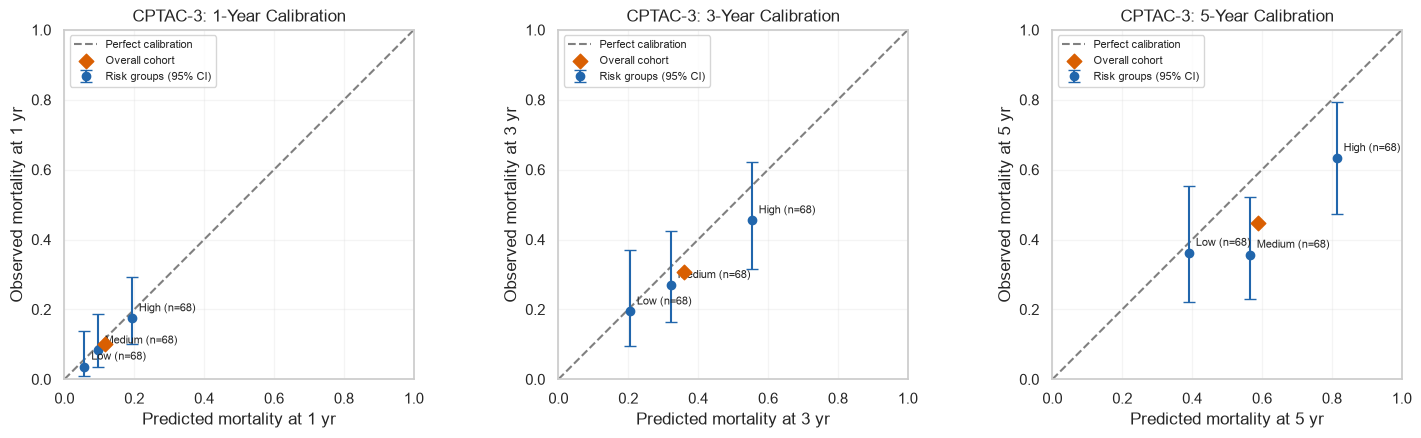

In [23]:
years = [1, 3, 5]
fig, axes = plt.subplots(1, len(years), figsize=(5 * len(years), 4.5))

for ax, yr in zip(axes, years):
    t_days = yr * 365.25
    
    pred_surv = cph.predict_survival_function(X_ext, times=[t_days]).iloc[0].values
    df_yr = external_valid[["overall_survival", "status"]].copy()
    df_yr["pred_risk"] = 1.0 - pred_surv
    df_yr["group"] = pd.qcut(df_yr["pred_risk"], q=3, labels=["Low", "Medium", "High"], duplicates="drop")
    
    ax.plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
    
    plotted_group = False
    for grp_name, grp in df_yr.groupby("group", observed=False):
        if len(grp) >= 10 and grp["overall_survival"].max() >= t_days:
            kmf = KaplanMeierFitter().fit(grp["overall_survival"], grp["status"])
            obs_risk = 1.0 - float(kmf.predict(t_days))
            ci = kmf.confidence_interval_survival_function_.loc[:t_days].iloc[-1]
            
            yerr = np.array([[obs_risk - (1.0 - ci.iloc[1])], [(1.0 - ci.iloc[0]) - obs_risk]]).clip(min=0)
            p_mean = grp["pred_risk"].mean()
            
            ax.errorbar(
                p_mean, obs_risk, yerr=yerr, fmt="o", color="#2166ac", capsize=4,
                label="Risk groups (95% CI)" if not plotted_group else ""
            )
            ax.annotate(f"{grp_name} (n={len(grp)})", (p_mean, obs_risk), xytext=(5, 5), textcoords="offset points", fontsize=8)
            plotted_group = True
            
    kmf_all = KaplanMeierFitter().fit(df_yr["overall_survival"], df_yr["status"])
    obs_all = 1.0 - float(kmf_all.predict(t_days))
    ax.scatter(df_yr["pred_risk"].mean(), obs_all, color="#d95f02", marker="D", s=55, zorder=5, label="Overall cohort")
    
    ax.set(
        xlim=(0, 1), ylim=(0, 1), aspect="equal",
        xlabel=f"Predicted mortality at {yr} yr",
        ylabel=f"Observed mortality at {yr} yr",
        title=f"CPTAC-3: {yr}-Year Calibration"
    )
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left", fontsize=8)

plt.tight_layout()
plt.show()